# LeNet 手写数字识别与平移鲁棒性实验

薛昕瑶 · 202410315005 · 人工智能241

本笔记本展示本仓库保存的实际训练记录、逐样本预测和可视化。三组模型共享数据划分、初始权重、训练预算和批次顺序。A 组采用参考结构中的 Sigmoid 和平均池化，B 组只把激活替换成 ReLU，C 组在 B 组上增加训练时 ±2 像素整数平移。

完整训练入口在 `run_experiment.py`。默认执行模式读取已完成的实验结果，打开下方的 `RUN_TRAINING` 开关可重新训练。

In [1]:
from pathlib import Path
import csv
import json
import platform
import subprocess
import sys
import numpy as np
from IPython.display import Code, HTML, Image, display

ROOT = Path.cwd()
if not (ROOT / 'run_experiment.py').exists():
    raise FileNotFoundError('请在仓库根目录打开本笔记本。')
RESULTS = ROOT / 'results'
summary = json.loads((RESULTS / 'summary.json').read_text(encoding='utf-8'))
MODELS = ('baseline', 'relu', 'shift')
NAMES = {'baseline': 'A 原始 Sigmoid', 'relu': 'B ReLU', 'shift': 'C ReLU + 平移增强'}
print('本次笔记本执行环境', platform.python_version())
print('保存的训练环境', json.dumps(summary['environment'], ensure_ascii=False))
print('三组实跑训练轮数', summary['config']['epochs'])

本次笔记本执行环境 3.13.9
保存的训练环境 {"python": "3.10.21", "pytorch": "2.15.0.dev20260923+cpu", "torchvision": "0.30.0.dev20260922+cpu", "numpy": "2.2.6", "device": "cpu", "threads": 4, "platform": "Windows-10-10.0.26200-SP0"}
三组实跑训练轮数 15


## 数据与评估协议

从 MNIST 官方 60,000 张训练样本中，每类固定抽取 500 张作为验证集，保留 55,000 张训练样本。官方 10,000 张测试样本在三组训练和验证选择全部完成后使用。模型以最低验证交叉熵对应的权重作为最终检查点。数据仅按像素值除以 255 预处理。

训练数据增强仅用于 C 组，采用独立随机整数 dx、dy ∈ [−2,2] 并以零填充。测试扰动预先固定为上、下、左、右各平移 2 像素。

In [2]:
split = summary['data_split']
assert (split['train'], split['validation'], split['test']) == (55000, 5000, 10000)
print(json.dumps(split, ensure_ascii=False, indent=2))
print(json.dumps(summary['config'], ensure_ascii=False, indent=2))
indices = np.load(RESULTS / 'split_indices.npz')
assert len(np.intersect1d(indices['train'], indices['validation'])) == 0
assert len(np.unique(np.concatenate([indices['train'], indices['validation']]))) == 60000
print('训练/验证索引互斥，合计覆盖 60,000 个官方训练样本。')

{
  "train": 55000,
  "validation": 5000,
  "test": 10000,
  "validation_per_class": 500,
  "sha256": "bea944120835e8941098faa6008859caafe1e286297718a2d41795c151027ee7",
  "train_per_class": [
    5423,
    6242,
    5458,
    5631,
    5342,
    4921,
    5418,
    5765,
    5351,
    5449
  ]
}
{
  "seed": 42,
  "epochs": 15,
  "batch_size": 512,
  "optimizer": "Adam",
  "learning_rate": 0.01,
  "selection": "minimum validation cross entropy",
  "normalization": "pixel / 255",
  "training_translation": "independent integer dx,dy sampled uniformly from [-2,2]",
  "test_translation": {
    "up": [
      0,
      -2
    ],
    "down": [
      0,
      2
    ],
    "left": [
      -2,
      0
    ],
    "right": [
      2,
      0
    ]
  }
}
训练/验证索引互斥，合计覆盖 60,000 个官方训练样本。


## 网络结构与实现

空间尺寸依次为 `1×28×28 → 6×28×28 → 6×14×14 → 16×10×10 → 16×5×5`，展平后经过 `400 → 120 → 84 → 10`。三组参数量均为 61,706。分类层输出 logits，训练损失使用交叉熵。

下面显示实际使用的模型文件。`features` 方法明确返回两层激活及对应平均池化结果。

In [3]:
for name in MODELS:
    assert summary['models'][name]['parameter_count'] == 61706
print('每组参数量', {name: summary['models'][name]['parameter_count'] for name in MODELS})
display(Code(filename=str(ROOT / 'model.py'), language='python'))

每组参数量 {'baseline': 61706, 'relu': 61706, 'shift': 61706}


"""LeNet-style classifier with a controlled activation-function ablation."""

import torch
from torch import nn
from torch.nn import functional as F


class LeNet(nn.Module):
    """The reference layer sizes, with either sigmoid or ReLU activations."""

    def __init__(self, activation="sigmoid"):
        super().__init__()
        if activation not in {"sigmoid", "relu"}:
            raise ValueError("activation must be sigmoid or relu")
        self.activation_name = activation
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.classifier = nn.Linear(84, 10)

    def activate(self, x):
        return torch.sigmoid(x) if self.activation_name == "sigmoid" else F.relu(x)

    def features(self, x):
        """Expose the post-activation feature maps and average-pooled maps."""
        conv1 = self.activate(self.conv1(x))
        pool1 = F.avg_pool2d(conv1, kernel_size=2, stride=2)
        conv2 = self.activate(self.conv2(pool1))
        pool2 = F.avg_pool2d(conv2, kernel_size=2, stride=2)
        return {"conv1": conv1, "pool1": pool1, "conv2": conv2, "pool2": pool2}

    def forward(self, x):
        x = self.features(x)["pool2"]
        x = torch.flatten(x, start_dim=1)
        x = self.activate(self.fc1(x))
        x = self.activate(self.fc2(x))
        return self.classifier(x)


def integer_translate(images, dx, dy, max_shift=2):
    """Translate each image using zero padding, with no wrap-around.

    Positive dx moves the ink right and positive dy moves it down. dx and dy
    may be integers or a tensor containing one displacement per image.
    """
    count, channels, height, width = images.shape
    dx = torch.as_tensor(dx, device=images.device).expand(count)
    dy = torch.as_tensor(dy, device=images.device).expand(count)
    if torch.any(dx.abs() > max_shift) or torch.any(dy.abs() > max_shift):
        raise ValueError("Translation exceeds the configured padding")
    padded = F.pad(images, (max_shift, max_shift, max_shift, max_shift))
    source_y = torch.arange(height, device=images.device)[None, :, None] + max_shift - dy[:, None, None]
    source_x = torch.arange(width, device=images.device)[None, None, :] + max_shift - dx[:, None, None]
    index = (source_y * padded.shape[-1] + source_x).reshape(count, 1, -1)
    index = index.expand(count, channels, -1)
    return padded.flatten(start_dim=2).gather(2, index).reshape_as(images)

## 训练入口

完整运行会重新生成 `results` 和 `checkpoints` 中的实验文件。默认开关为 False，当前笔记本读取已实跑并保存的记录。需要重训时，将开关设为 True 后从该单元继续执行。

In [4]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, 'run_experiment.py', '--epochs', '15',
                    '--batch-size', '512', '--threads', '4', '--seed', '42'],
                   cwd=ROOT, check=True)
    summary = json.loads((RESULTS / 'summary.json').read_text(encoding='utf-8'))
else:
    print('读取已完成的真实训练结果。训练轮数', summary['config']['epochs'])

# 图表根据保存的原始数值重新生成。
subprocess.run([sys.executable, 'make_figures.py'], cwd=ROOT, check=True)
print('图表生成完成。')

读取已完成的真实训练结果。训练轮数 15


图表生成完成。


## 验证选择与训练曲线

损失按样本数加权。训练损失与验证损失的统计时点不同，前者在每轮参数更新过程中累计，后者在该轮训练结束后计算。C 组训练指标包含随机平移增强，因此也应结合验证曲线解读。图中验证损失圆点表示各组选中的轮次。

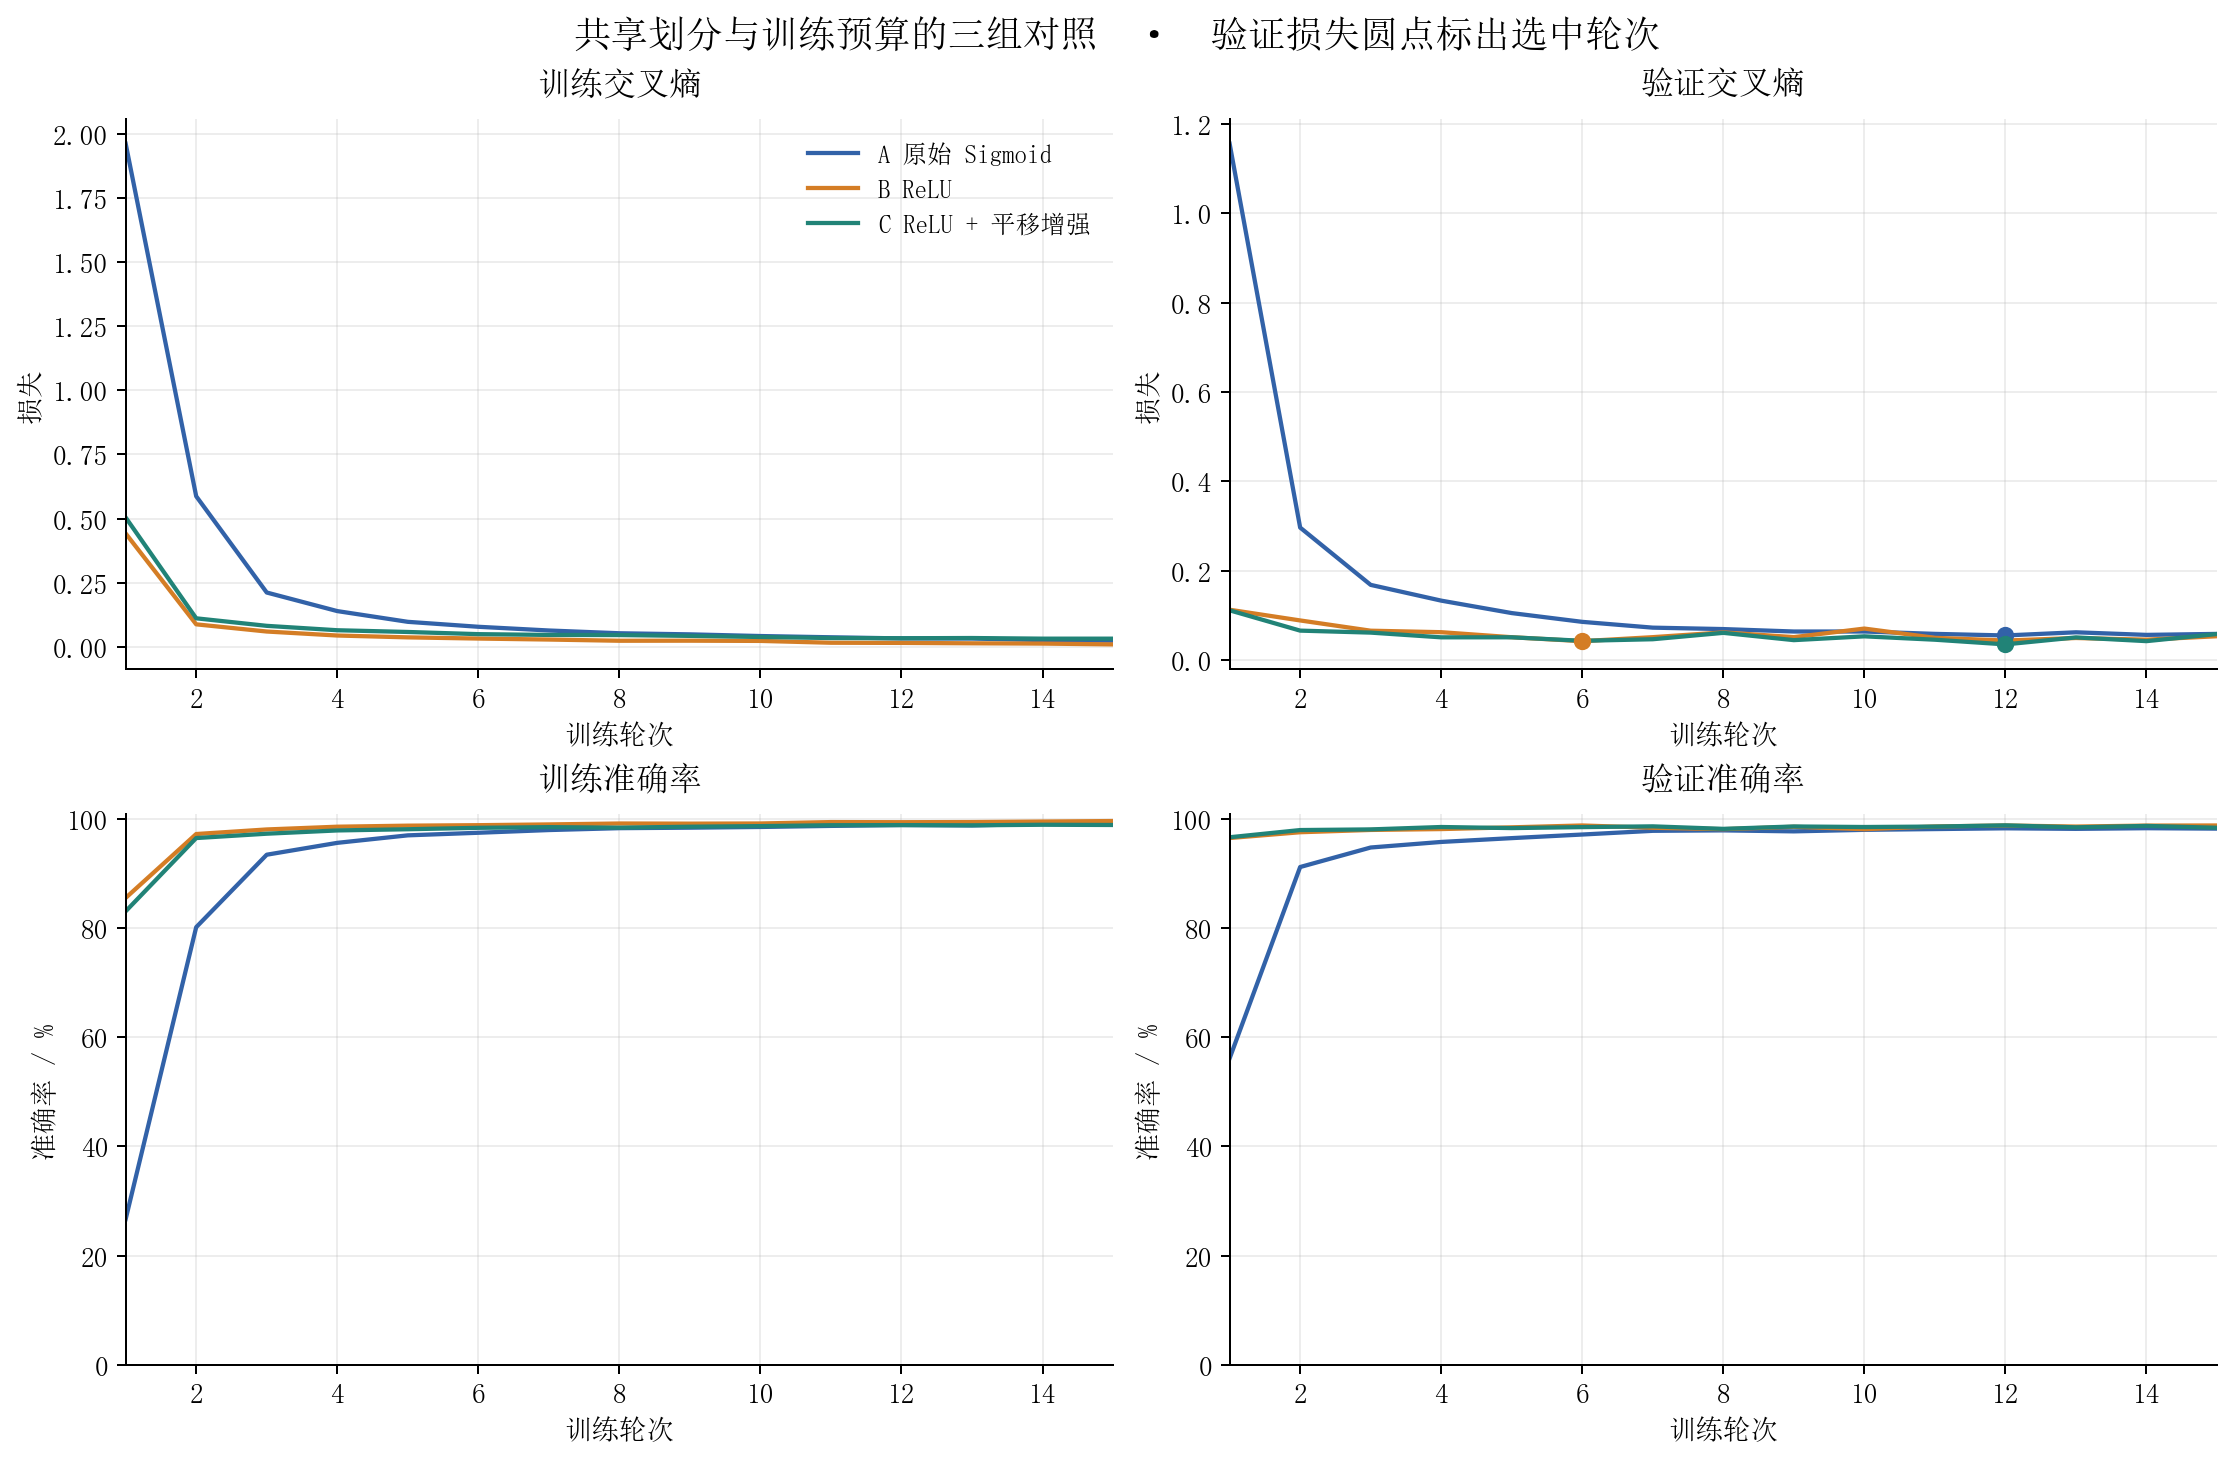

A 原始 Sigmoid 选中轮次 12 验证损失 0.05572 训练耗时/秒 297.2
B ReLU 选中轮次 6 验证损失 0.042987 训练耗时/秒 111.1
C ReLU + 平移增强 选中轮次 12 验证损失 0.03575 训练耗时/秒 62.9


In [5]:
display(Image(filename=str(RESULTS / 'figures' / 'learning_curves.png')))
for name in MODELS:
    record = summary['models'][name]
    print(NAMES[name], '选中轮次', record['best_epoch'],
          '验证损失', round(record['validation_loss'], 6),
          '训练耗时/秒', round(record['train_seconds'], 1))

## 预定测试集结果

准确率、宏平均 F1 和交叉熵反映不同的预测特征。下面的平移平均准确率是四个固定方向的准确率算术平均。模型间差异仅描述当前随机种子与固定划分下的一次实验。

模型,原图准确率,宏 F1,交叉熵,误判数,四向平移平均准确率
A 原始 Sigmoid,98.65%,0.98642,0.04631,135,93.16%
B ReLU,98.79%,0.98779,0.03678,121,93.66%
C ReLU + 平移增强,98.97%,0.98970,0.03325,103,98.84%


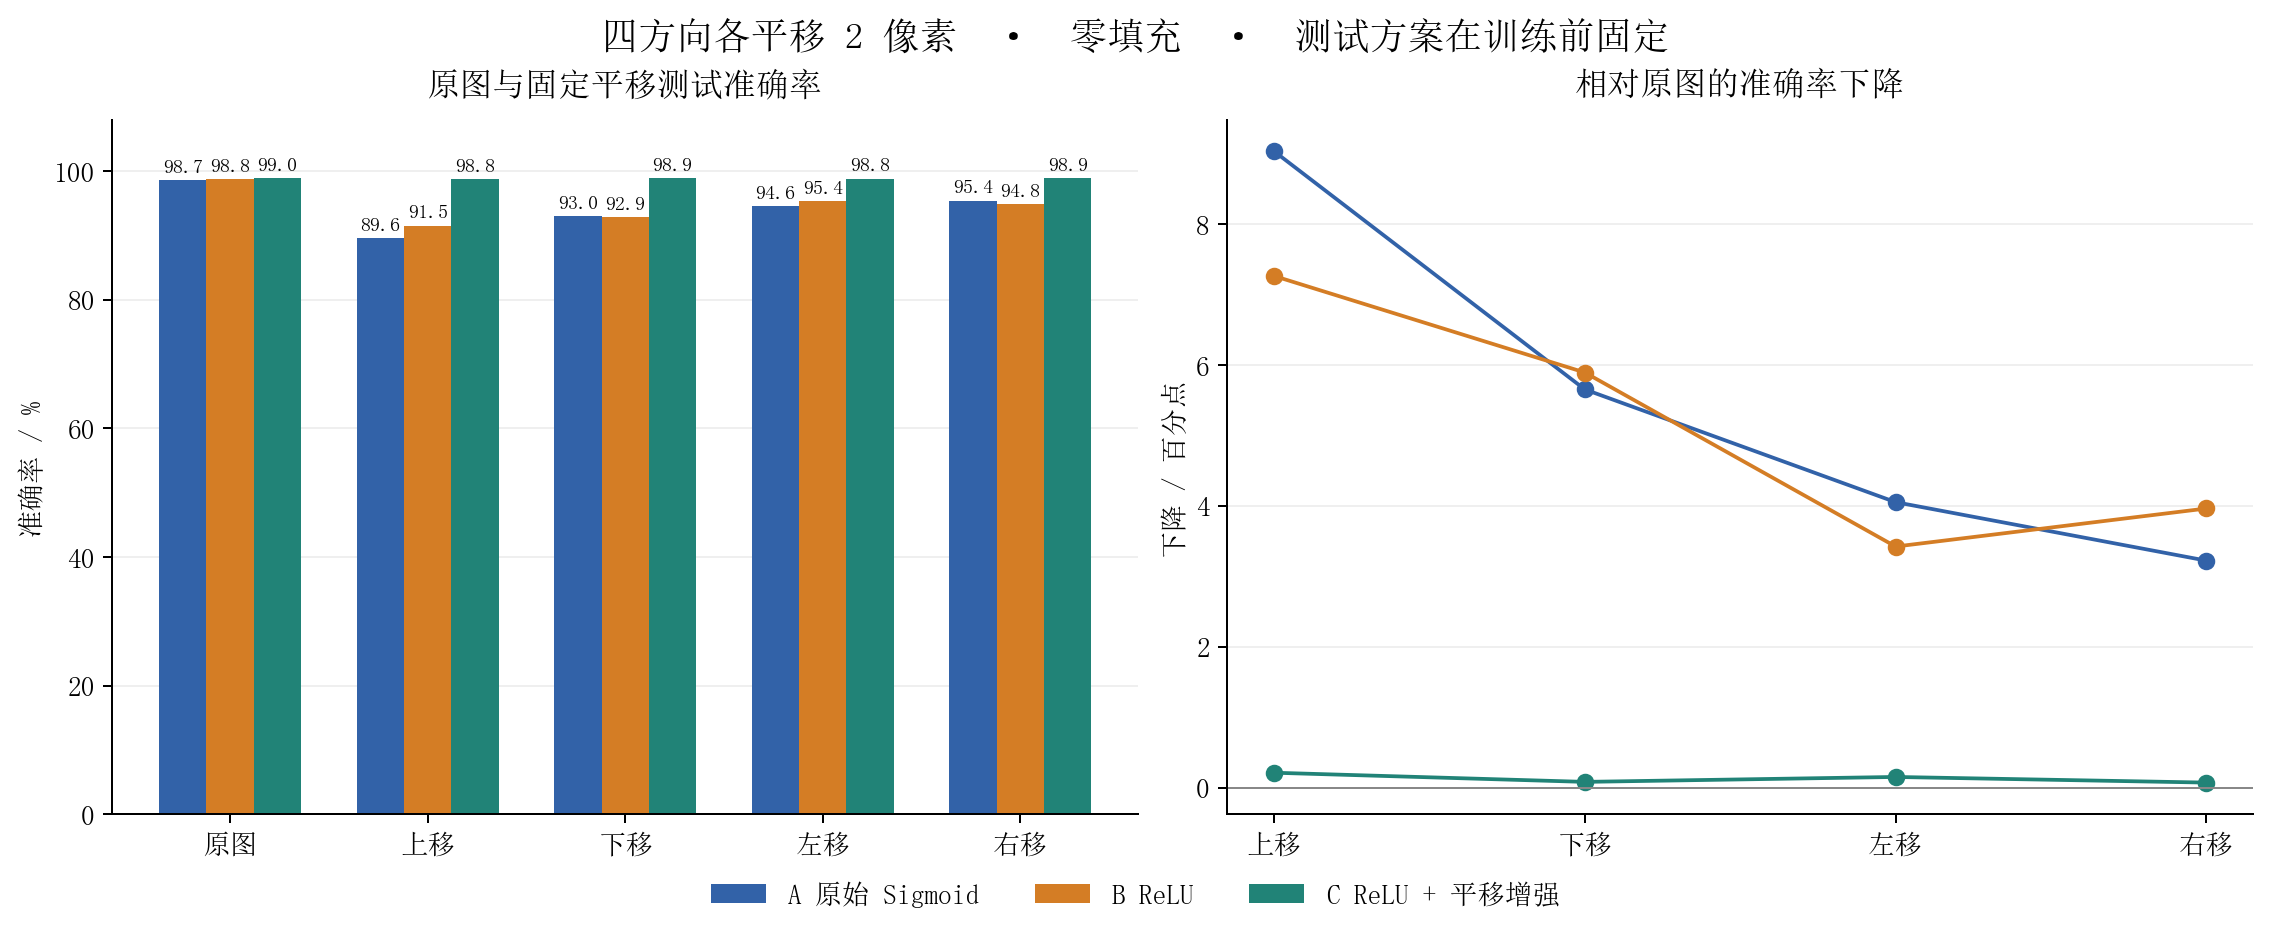

In [6]:
rows = []
for name in MODELS:
    record = summary['models'][name]
    clean = record['clean']
    rows.append('<tr><td>' + NAMES[name] + '</td>'
                + f"<td>{clean['accuracy']*100:.2f}%</td>"
                + f"<td>{clean['macro_f1']:.5f}</td>"
                + f"<td>{clean['loss']:.5f}</td>"
                + f"<td>{clean['total']-clean['correct']}</td>"
                + f"<td>{record['robustness']['mean_shift_accuracy']*100:.2f}%</td></tr>")
display(HTML('<table><thead><tr><th>模型</th><th>原图准确率</th><th>宏 F1</th><th>交叉熵</th><th>误判数</th><th>四向平移平均准确率</th></tr></thead><tbody>'
             + ''.join(rows) + '</tbody></table>'))
display(Image(filename=str(RESULTS / 'figures' / 'translation_robustness.png')))

## 分类错误分布与逐类 F1

混淆矩阵的行为真实类别、列为预测类别。下方 F1 图用于检查整体准确率是否掩盖个别数字类别的差异。

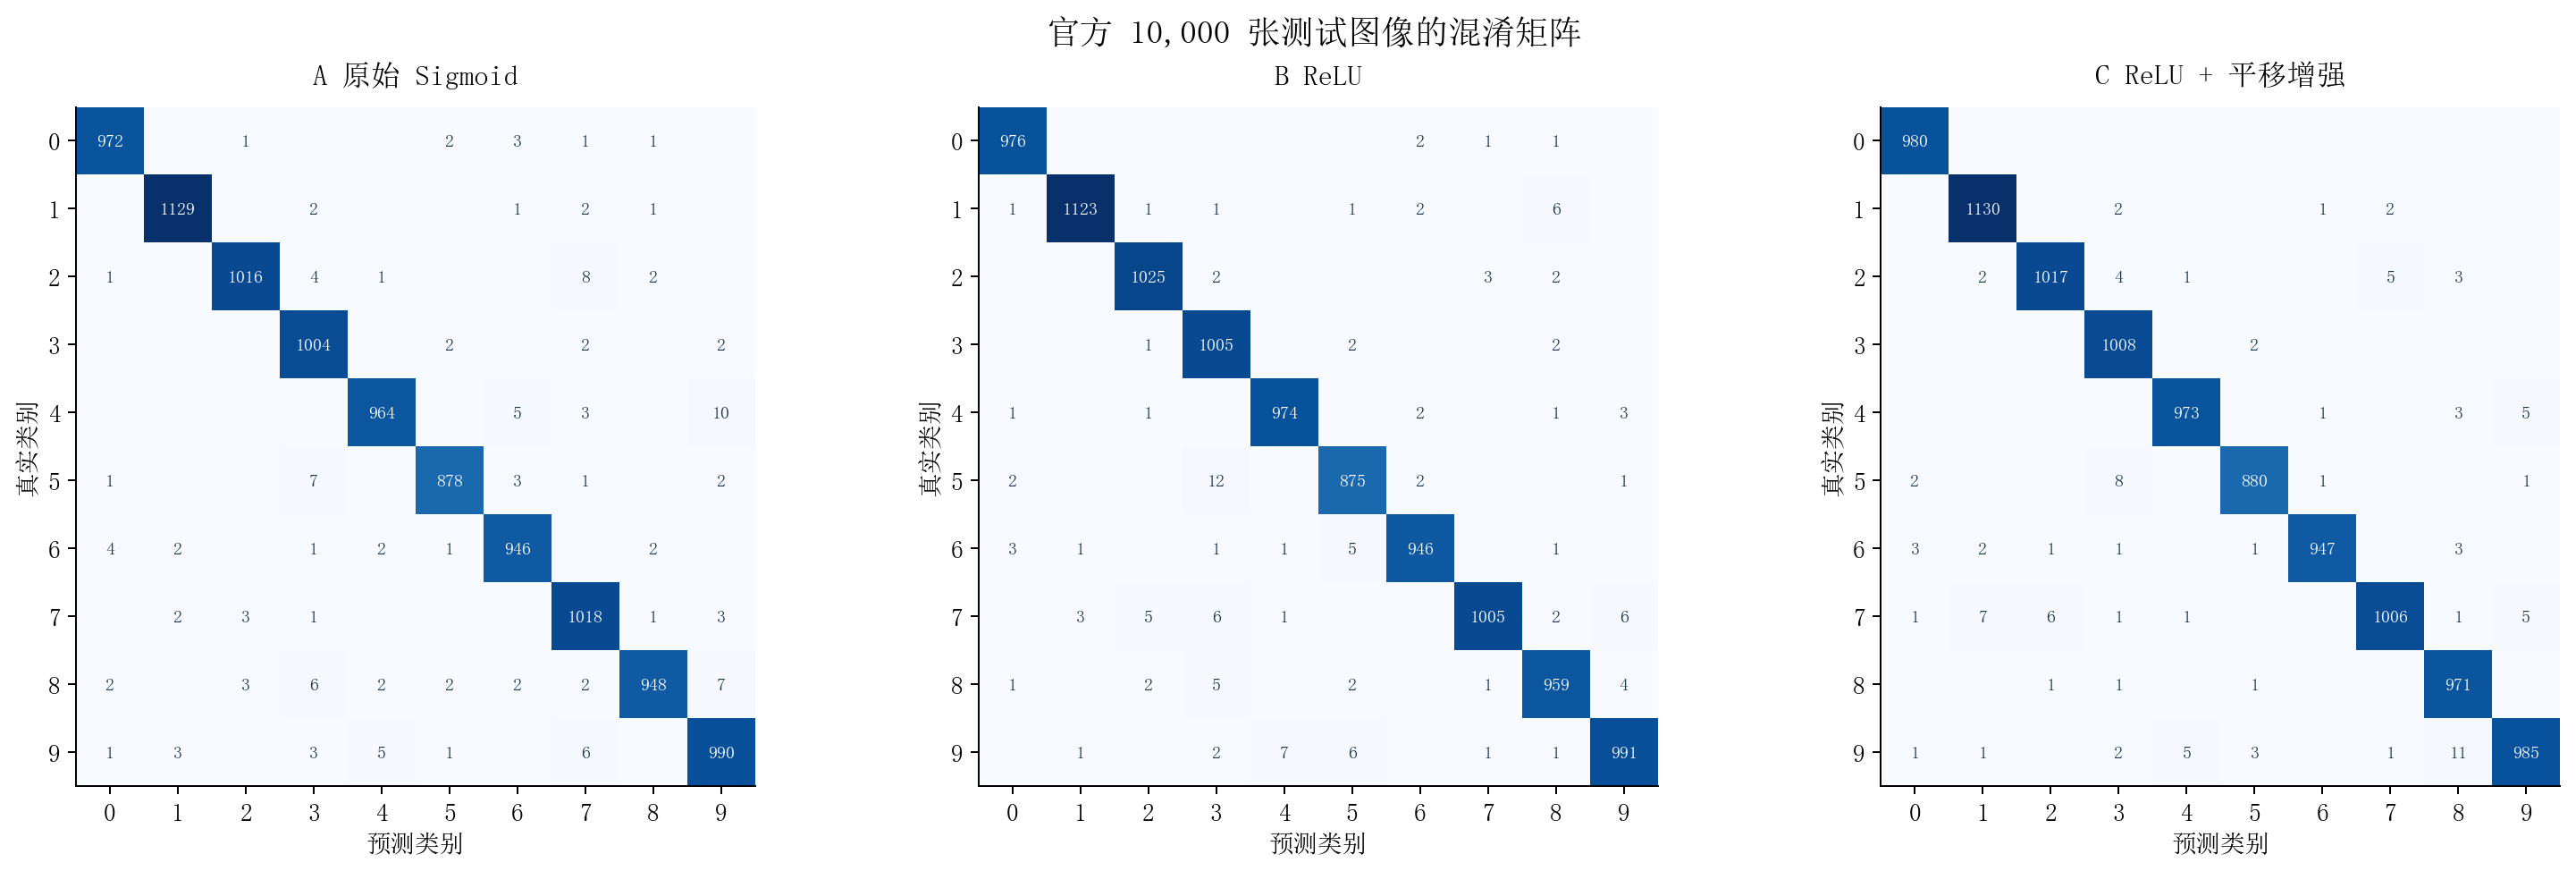

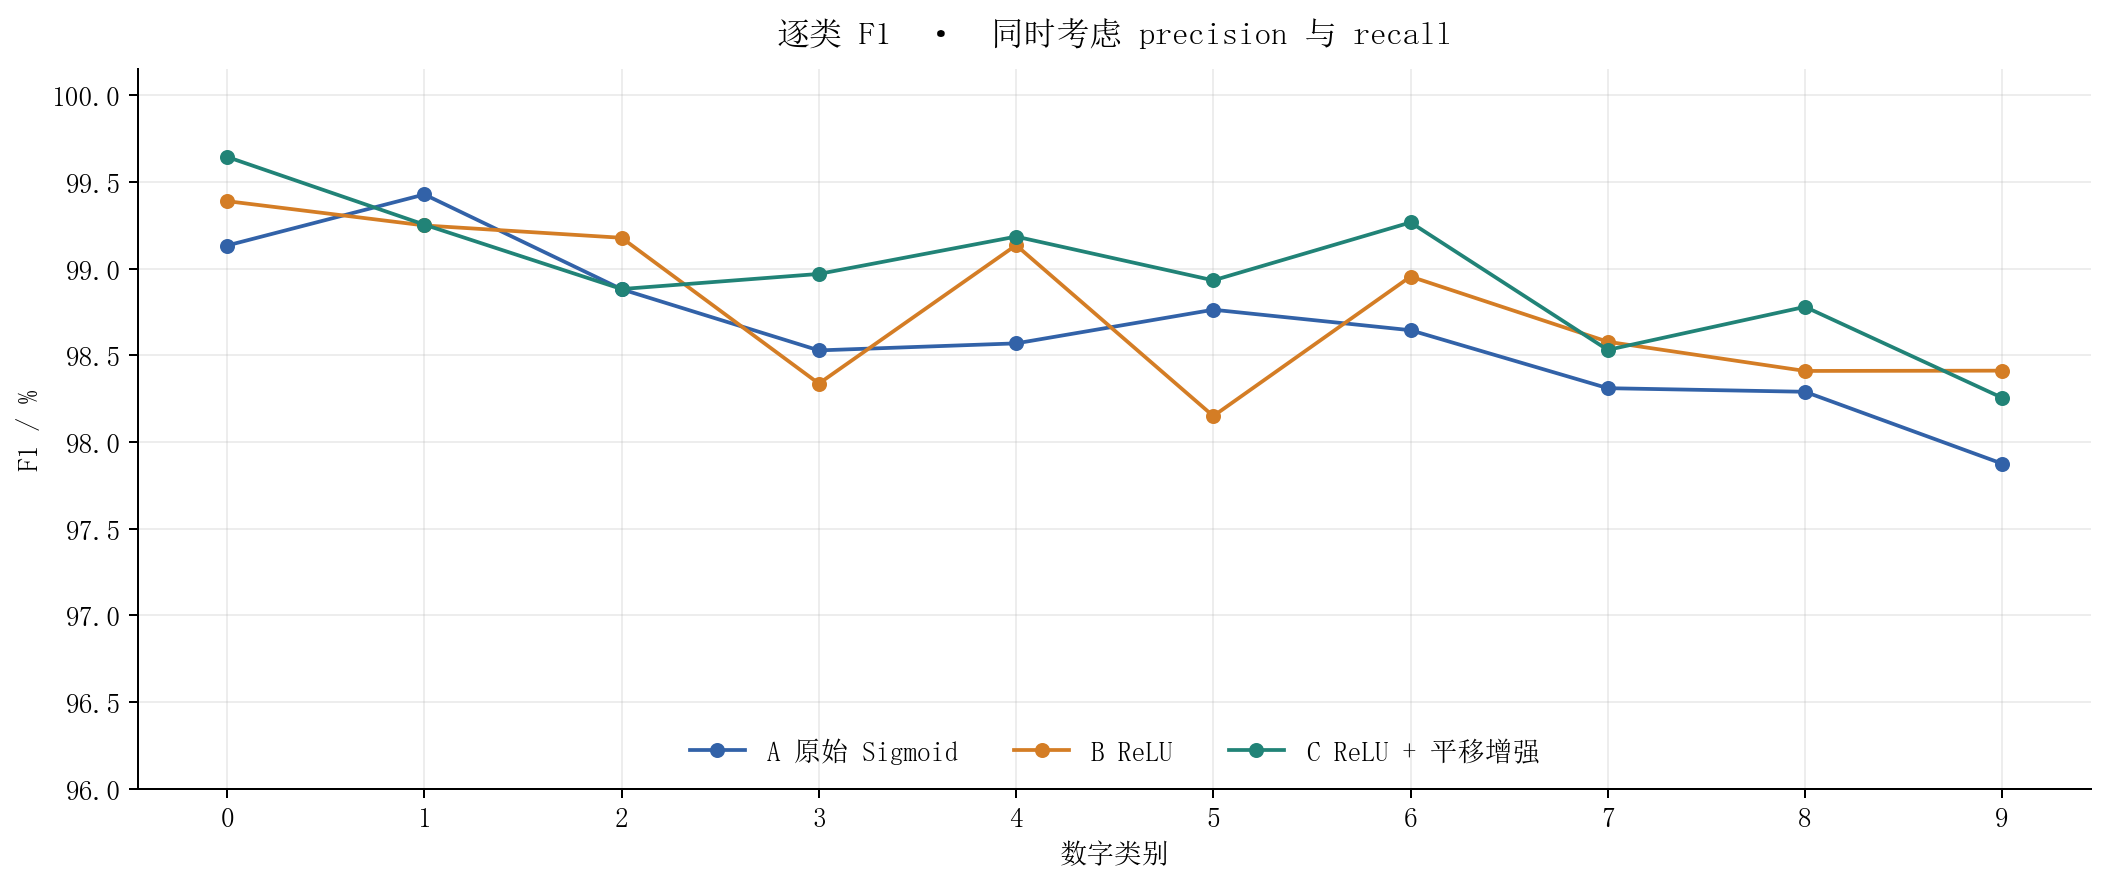

A 原始 Sigmoid 最多的定向混淆 4 → 9，共 10 张
B ReLU 最多的定向混淆 5 → 3，共 12 张
C ReLU + 平移增强 最多的定向混淆 9 → 8，共 11 张


In [7]:
display(Image(filename=str(RESULTS / 'figures' / 'confusion_matrices.png')))
display(Image(filename=str(RESULTS / 'figures' / 'class_f1.png')))
for name in MODELS:
    matrix = np.asarray(summary['models'][name]['clean']['confusion_matrix'])
    matrix = matrix.copy()
    np.fill_diagonal(matrix, 0)
    i, j = np.unravel_index(matrix.argmax(), matrix.shape)
    print(NAMES[name], f'最多的定向混淆 {i} → {j}，共 {matrix[i,j]} 张')

## 高置信度误判与配对比较

误判画廊的选择规则固定为各组按错误预测置信度降序显示前 5 张，并显示官方测试索引。Softmax 置信度是模型给出的概率分配，单个高置信度结果仍可能判断错误。

配对计数直接比较同一批 10,000 张图像，分别统计一个模型判断正确而另一个判断错误的样本。这里只报告本次预测差异。

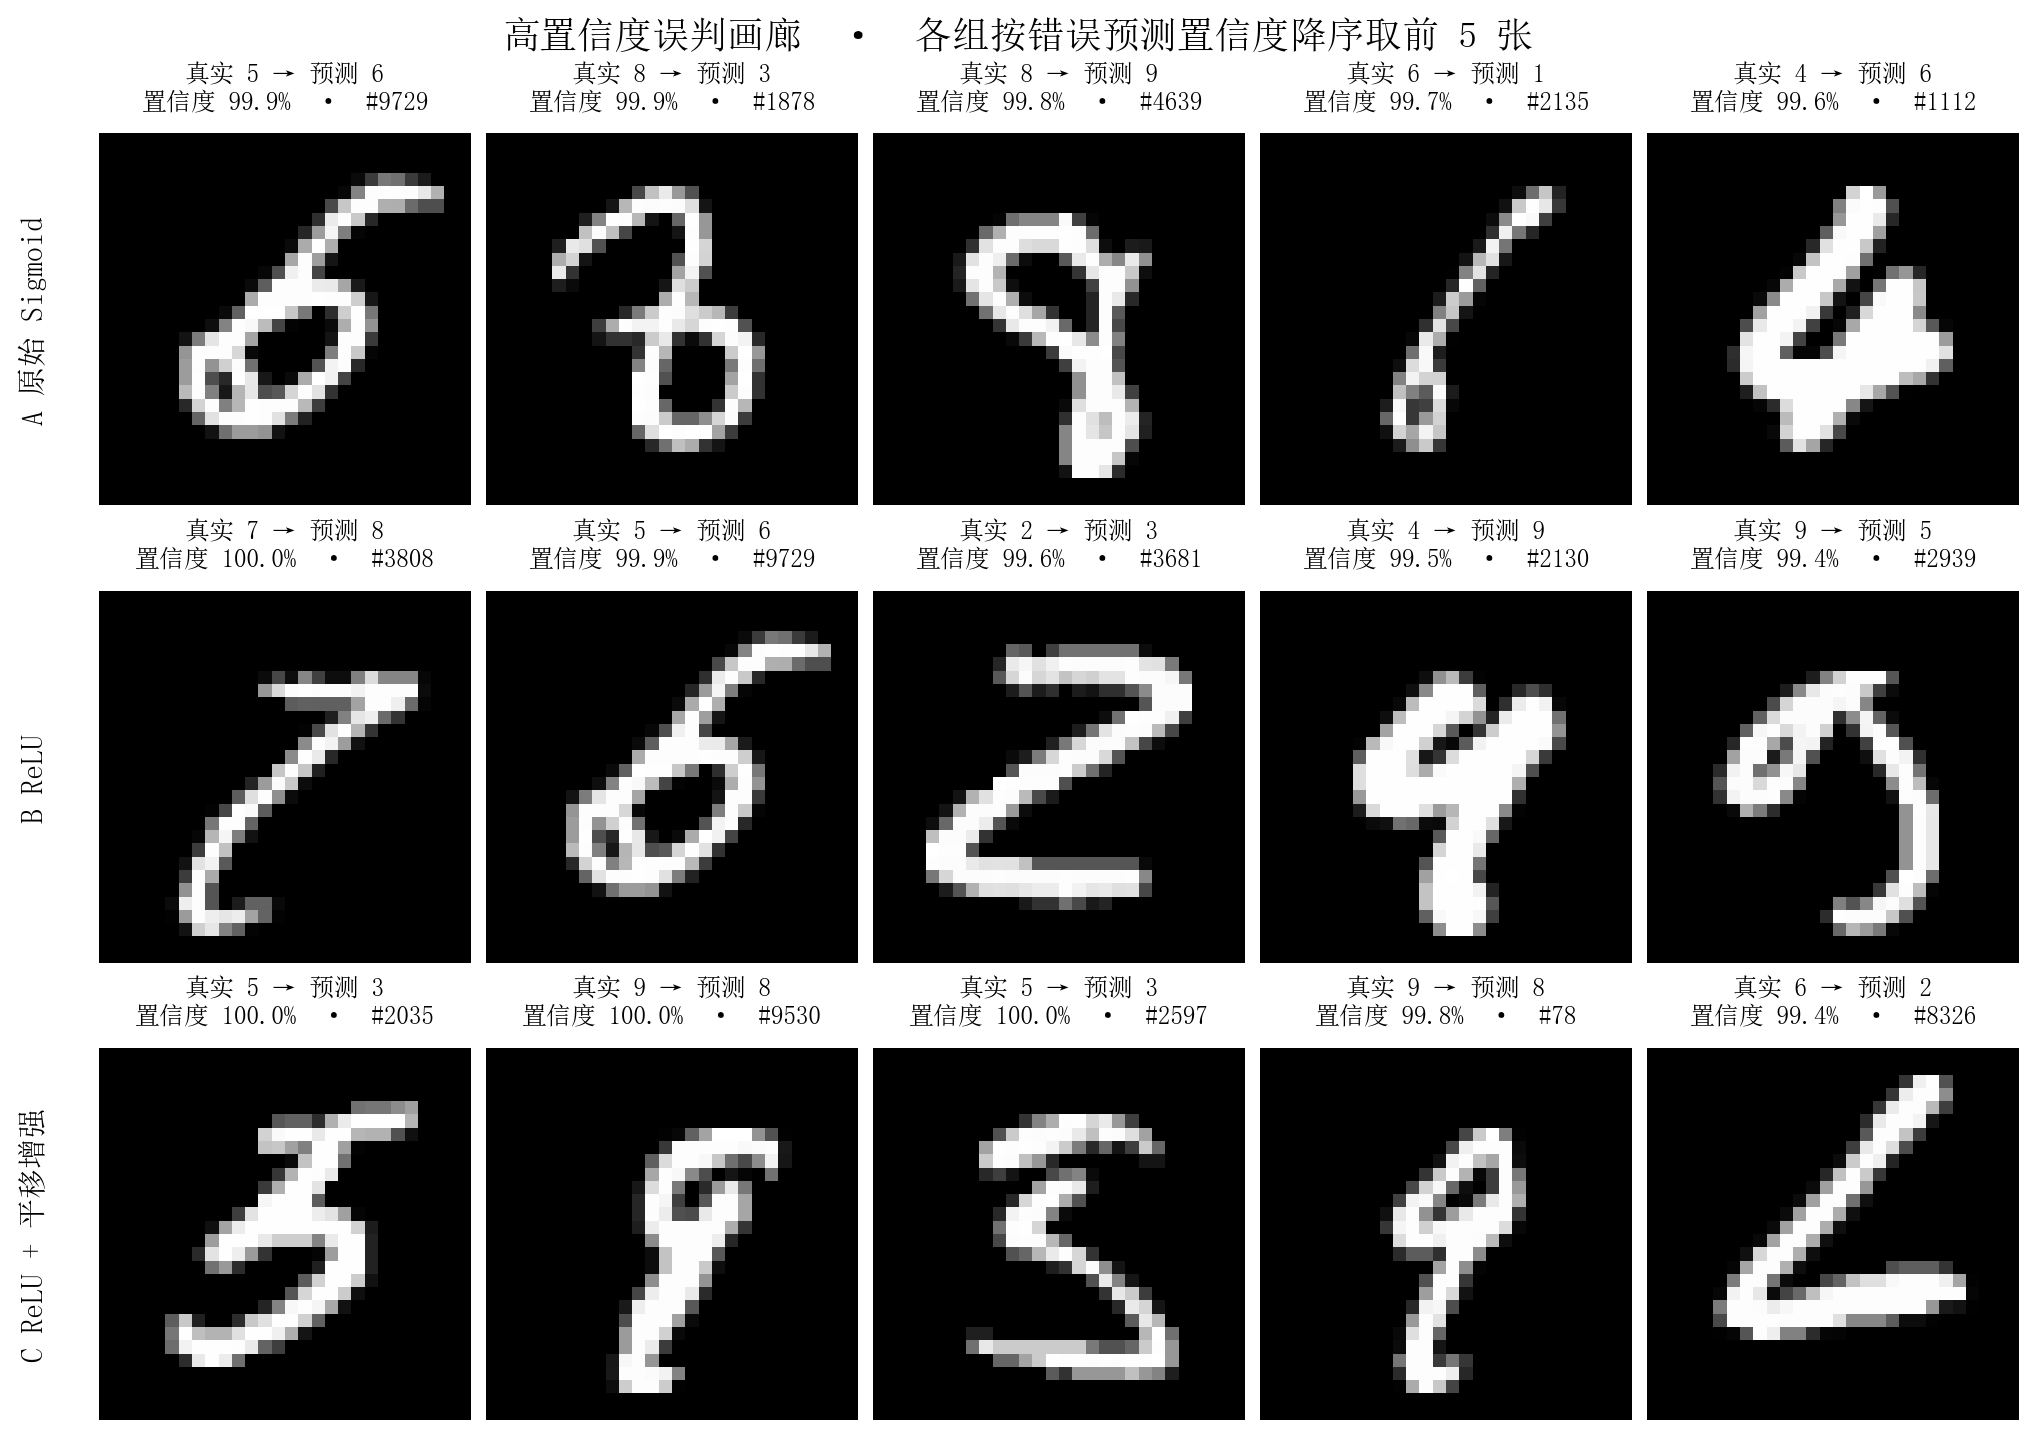

A 原始 Sigmoid 对 / B ReLU 错 63
A 原始 Sigmoid 错 / B ReLU 对 77
B ReLU 对 / C ReLU + 平移增强 错 57
B ReLU 错 / C ReLU + 平移增强 对 75


In [8]:
display(Image(filename=str(RESULTS / 'figures' / 'high_confidence_errors.png')))
with (RESULTS / 'predictions.csv').open(encoding='utf-8', newline='') as stream:
    predictions = list(csv.DictReader(stream))
truth = np.array([int(row['true']) for row in predictions])
pred = {name: np.array([int(row[f'{name}_pred']) for row in predictions]) for name in MODELS}
for left, right in [('baseline', 'relu'), ('relu', 'shift')]:
    a, b = pred[left] == truth, pred[right] == truth
    print(f'{NAMES[left]} 对 / {NAMES[right]} 错', int(np.sum(a & ~b)))
    print(f'{NAMES[left]} 错 / {NAMES[right]} 对', int(np.sum(~a & b)))

## 固定样本的卷积与池化激活

特征图展示 C 组模型对官方测试索引 0 的处理结果。每层所有通道共用该层的色标范围，各层独立缩放。卷积和池化的空间尺寸可由这些输出直接核对。可视化记录的是激活数值，具体通道的判别作用仍需额外实验验证。

conv1 形状 (6, 28, 28) 数值范围 0.0 2.6979422569274902
pool1 形状 (6, 14, 14) 数值范围 0.0 2.1229474544525146
conv2 形状 (16, 10, 10) 数值范围 0.0 4.043004512786865
pool2 形状 (16, 5, 5) 数值范围 0.0 2.6390480995178223


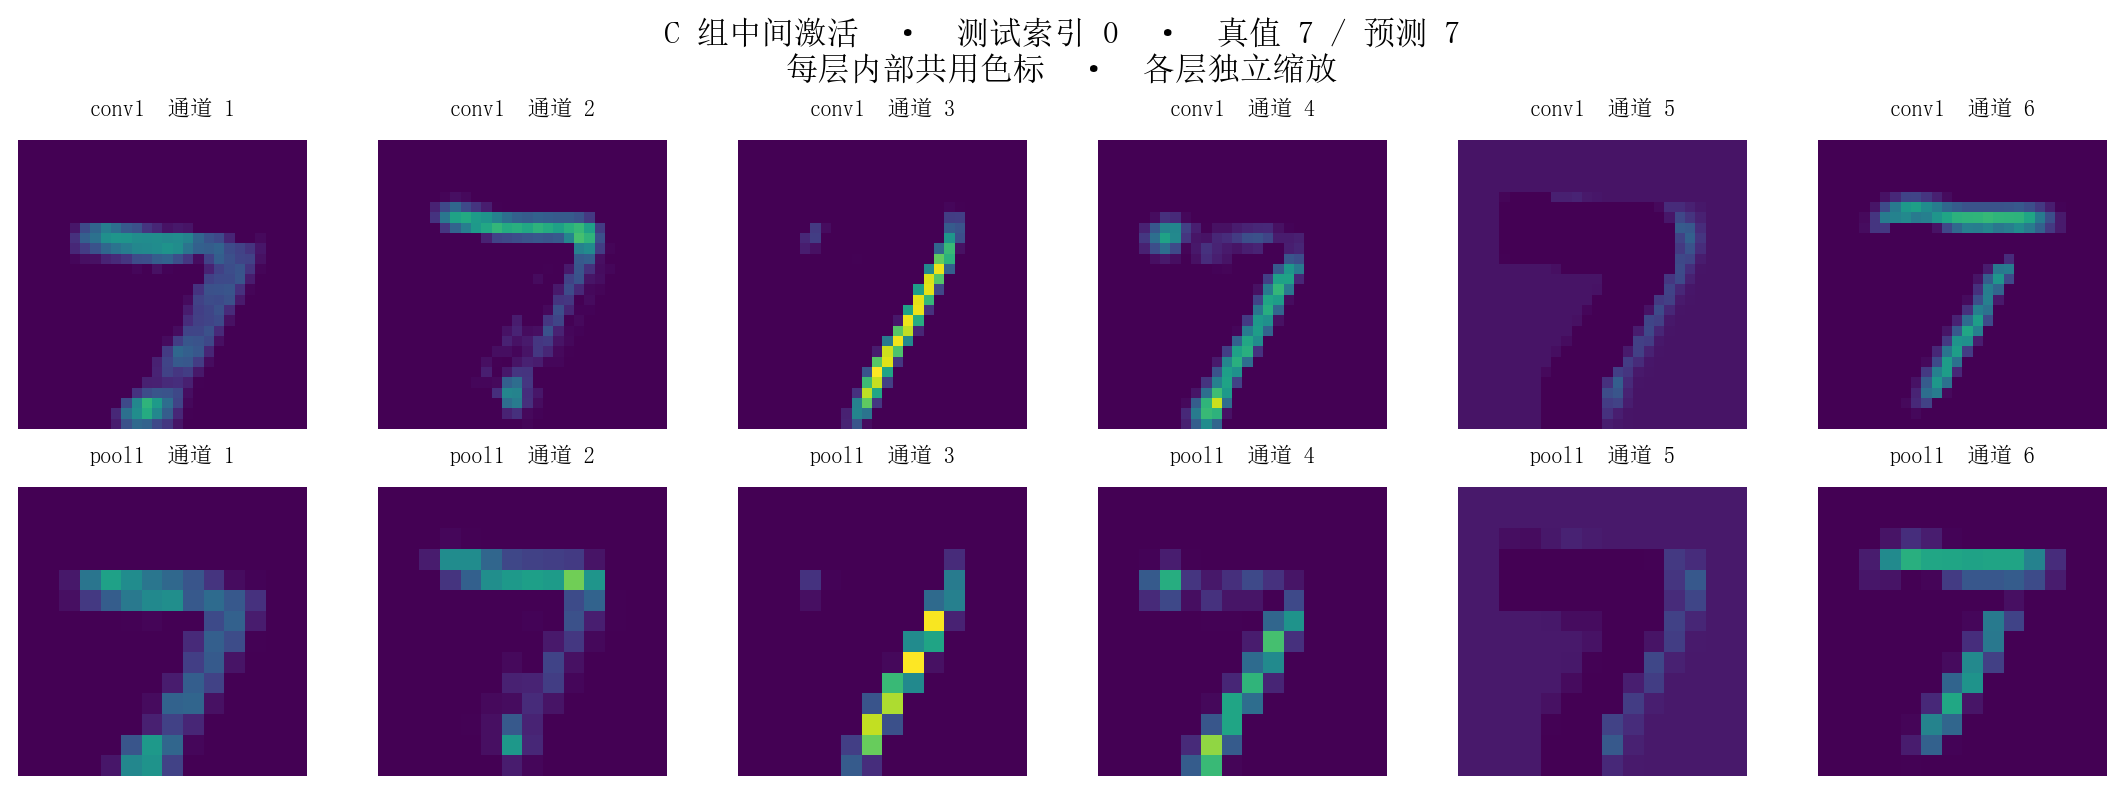

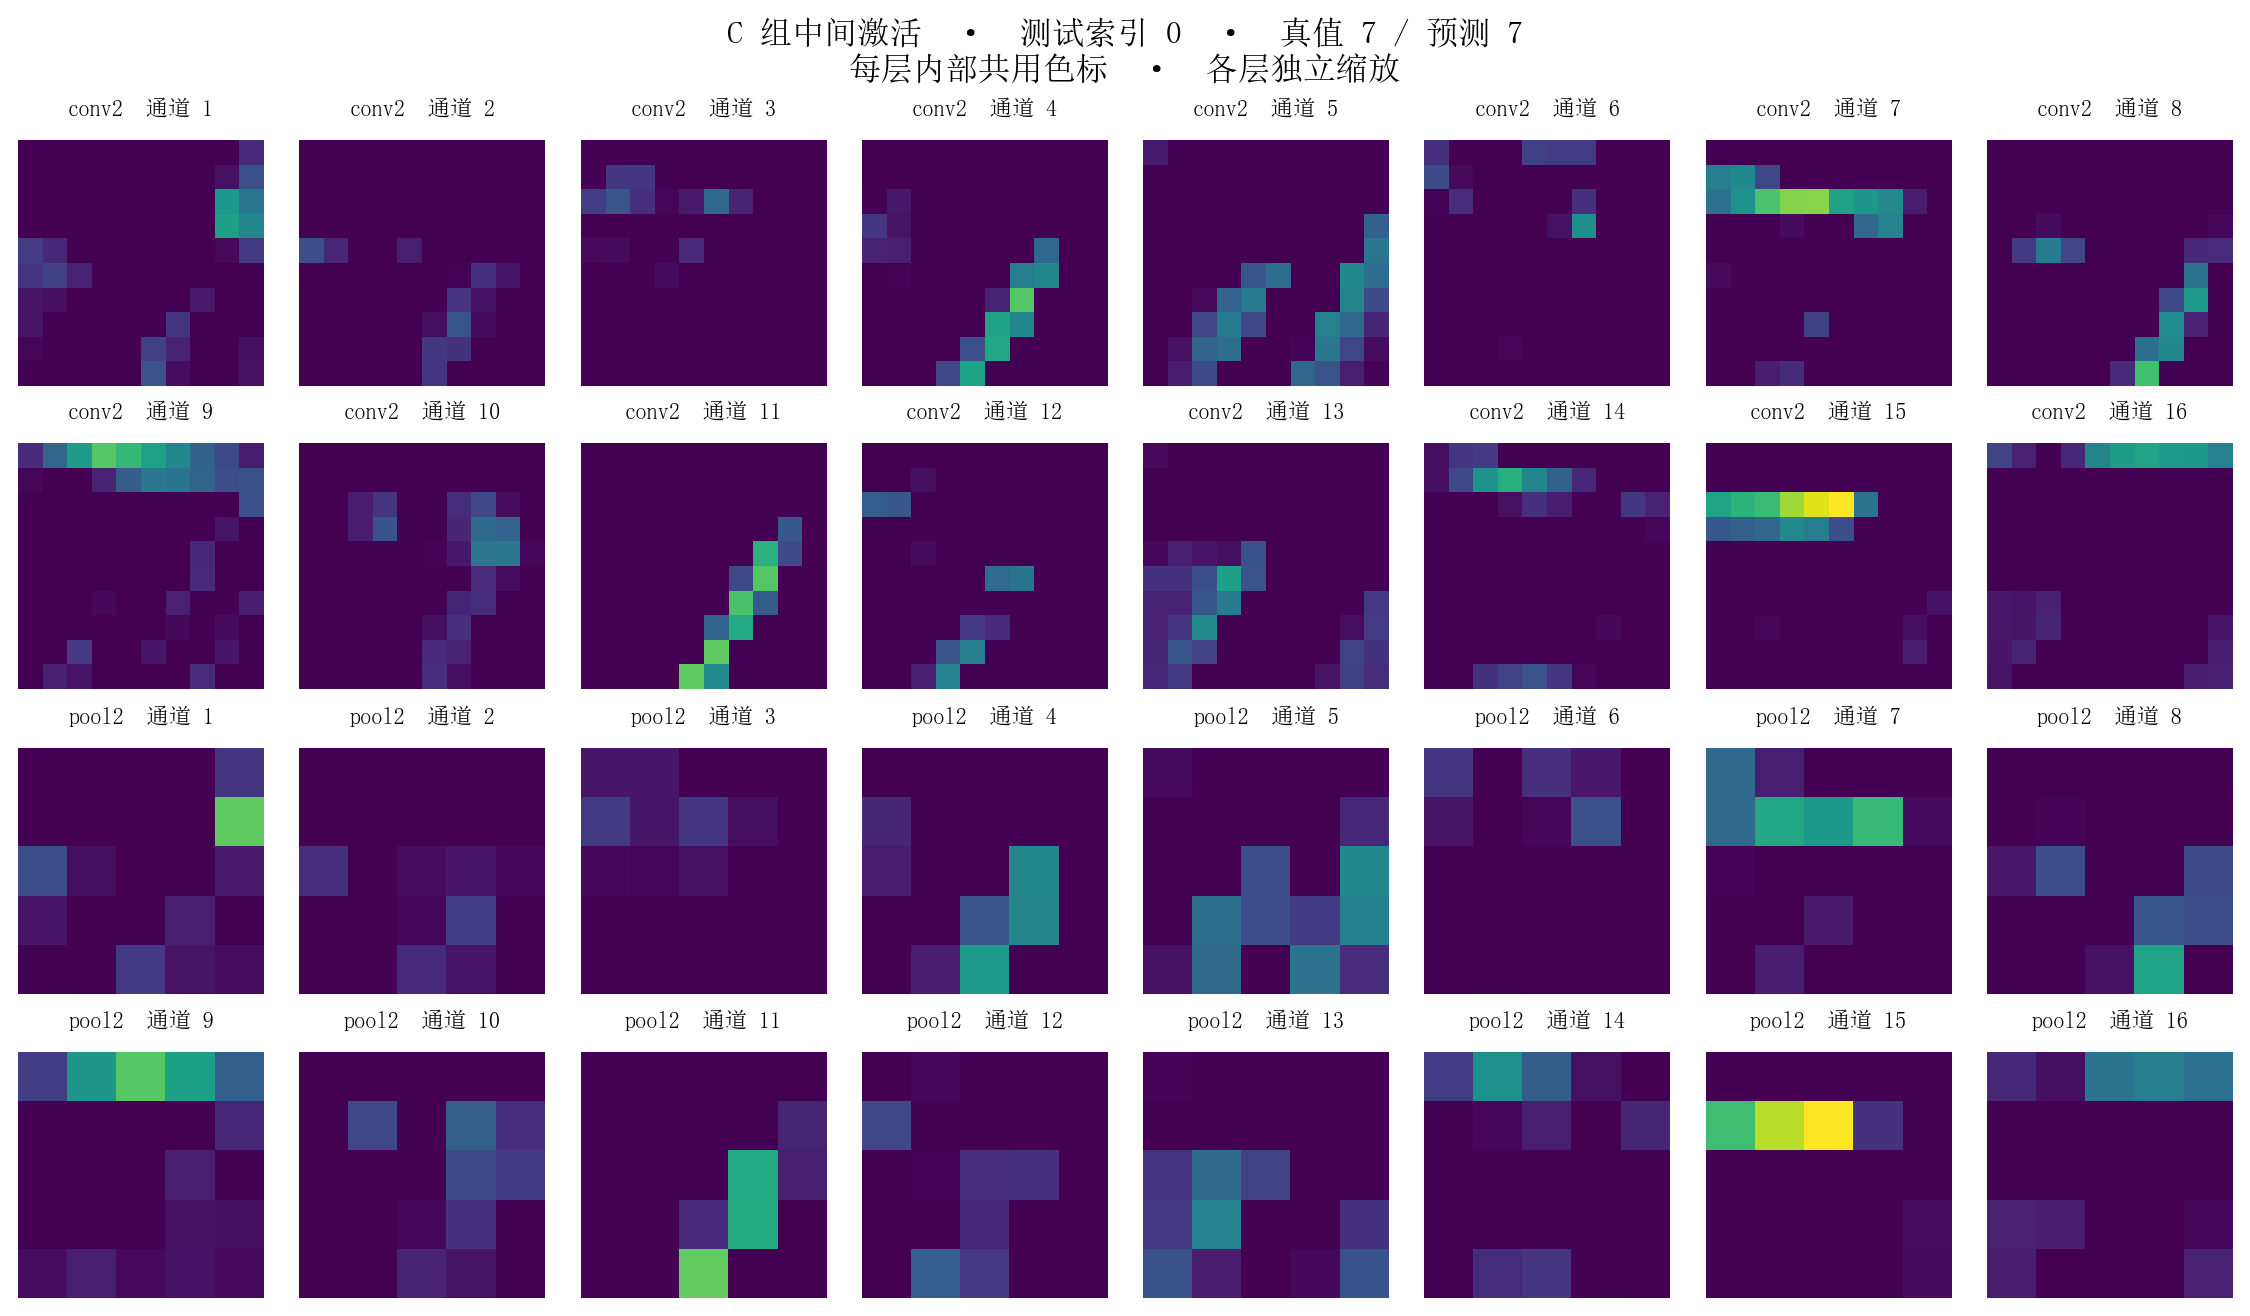

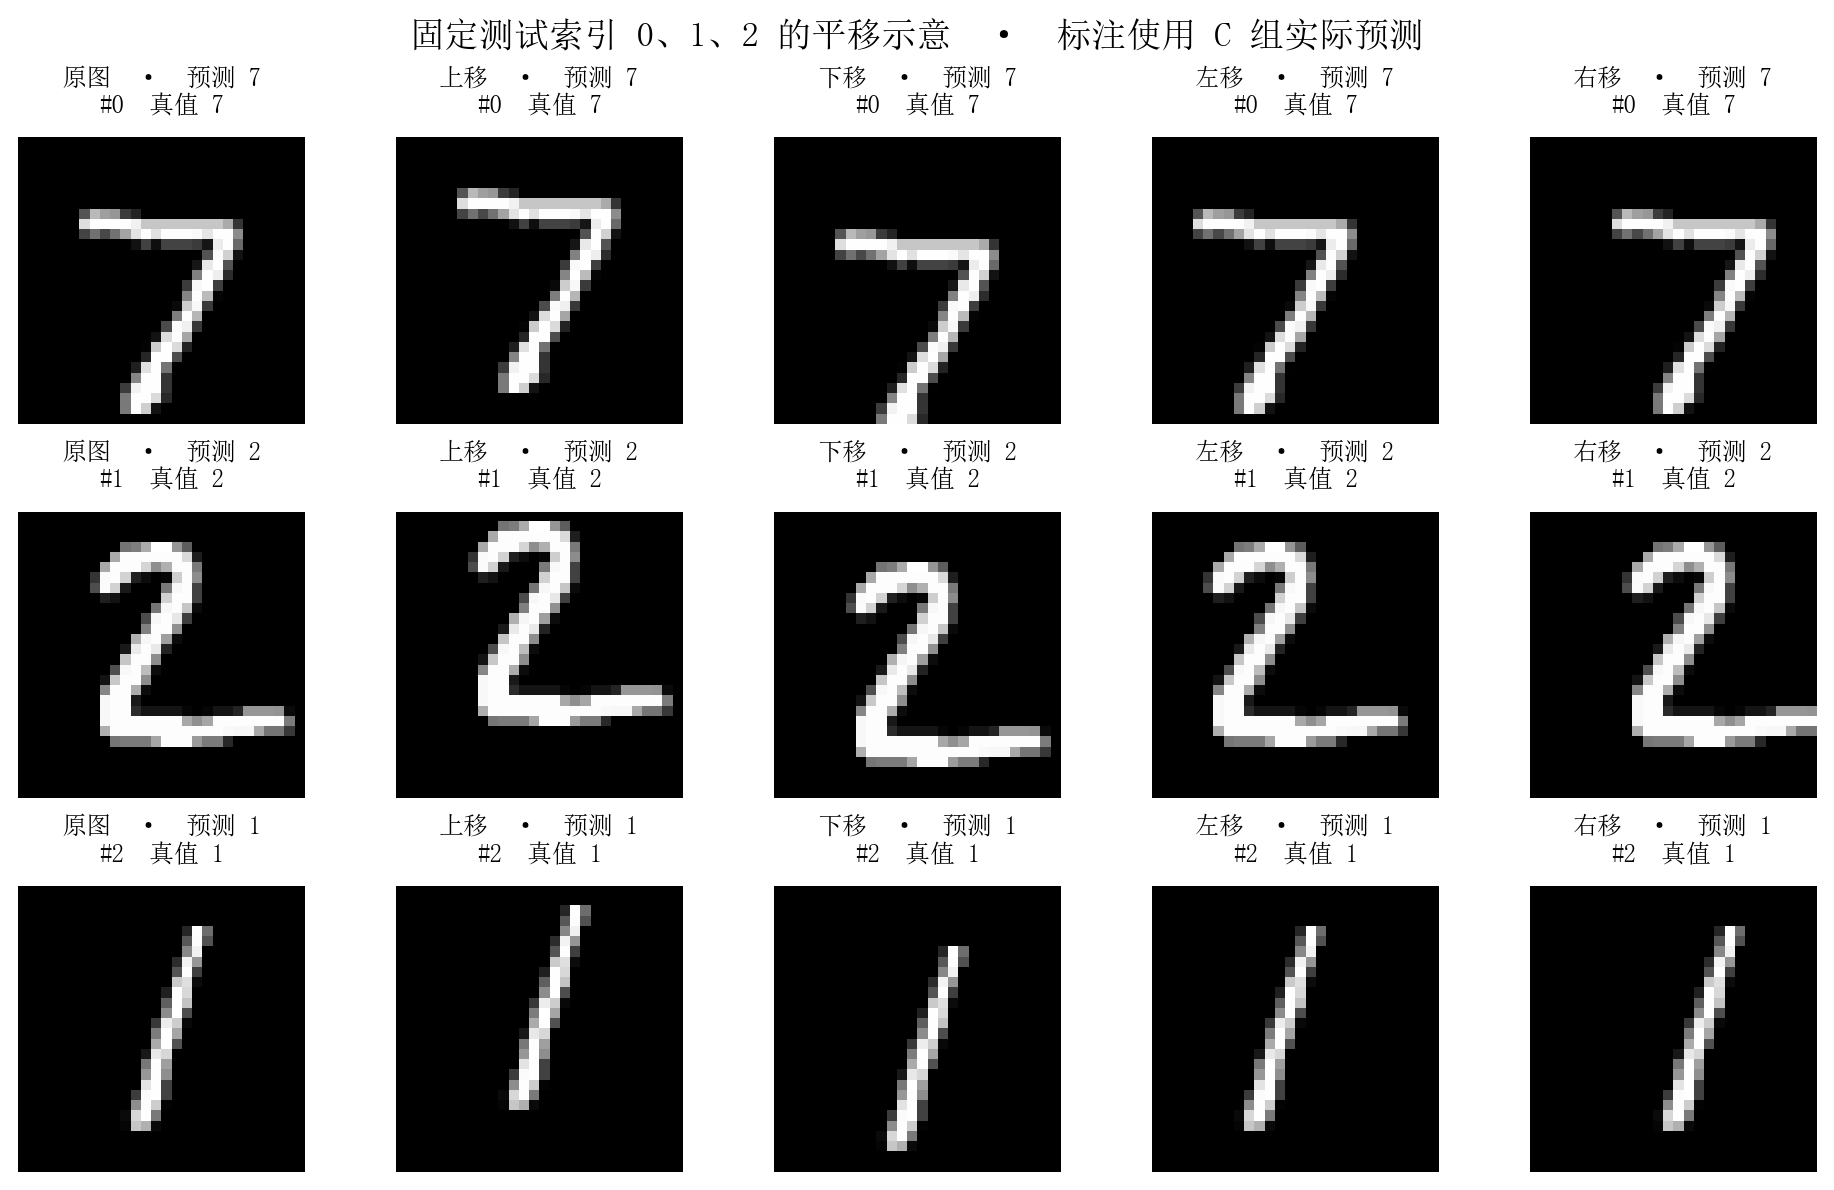

In [9]:
arrays = np.load(RESULTS / 'analysis.npz')
for layer in ('conv1', 'pool1', 'conv2', 'pool2'):
    values = arrays[f'shift_{layer}']
    print(layer, '形状', values.shape, '数值范围', float(values.min()), float(values.max()))
display(Image(filename=str(RESULTS / 'figures' / 'feature_maps_early.png')))
display(Image(filename=str(RESULTS / 'figures' / 'feature_maps_deep.png')))
display(Image(filename=str(RESULTS / 'figures' / 'input_translations.png')))

## 结果的适用范围

本实验使用一个随机种子、一个固定分层划分和相同的训练预算。测试扰动为四方向 2 像素平移，因此所得鲁棒性结论限定在该扰动定义下。验证集选模避免把每轮测试结果用于选择检查点。原始资料帮助确定网络层次和任务，本仓库独立实现训练、增强、验证选择与结果分析。

参考资料

- 课程提供的《实验五参考代码.pdf》。
- [顾禹东的实验五示例](https://github.com/Guyudong1/CV_exp/tree/main/5th.exp)。
- [PyTorch CrossEntropyLoss 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。
- [Torchvision MNIST 文档](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)。